# Notebook 3: LSIS-AFS Navigation Message

**LunaLink Reference Implementation — Pedagogical Notebook Series**

This notebook teaches the **navigation message** layer of the
[LunaNet](https://www.nasa.gov/humans-in-space/lunanet-empowering-artemis-with-communications-and-navigation-interoperability/) Signal-In-Space
Augmented Forward Signal (LSIS-AFS). By the end, you will understand how
navigation data is structured into frames, how time is encoded, and be able
to build and decode a complete 6,000-symbol frame yourself.

> **Spec reference:** LSIS-AFS Volume A, V1.0, §2.4 — *AFS Navigation Message Format Specification*
> and §2.5 — *AFS Messages and Data Content*
> ([CCSDS](https://public.ccsds.org/), 29 January 2025)

**Prerequisites:** [Notebook 1 (Spreading Codes)](01_spreading_codes.ipynb) and
[Notebook 2 (Error Correction)](02_error_correction.ipynb).

In [1]:
import matplotlib.pyplot as plt  # Plotting
import numpy as np  # Arrays

from lunalink import make_test_payload, receive_frame, transmit_frame
from lunalink.afs import (  # LunaLink API
    # Frame structure constants
    FRAME_LENGTH,  # 6000 symbols
    INTERLEAVER_COLS,  # 98
    # Interleaver
    INTERLEAVER_ROWS,  # 60
    INTERLEAVER_SIZE,  # 5880
    PAYLOAD_LENGTH,  # 5880 symbols
    SB1_LENGTH,  # 52 symbols
    # Subframe sizes
    SB2_DATA_BITS,  # 1176 data bits
    SB2_LENGTH,  # 2400 encoded symbols
    SB3_DATA_BITS,  # 846 data bits
    SB3_LENGTH,  # 1740 encoded symbols
    SYNC_LENGTH,  # 68 symbols
    bch_decode,  # BCH hard decoder
    bch_encode,  # BCH(51,8) encoder
    compute_tot,  # Time of Transmission
    frame_build,  # Build complete frame
    # Message parsing
    parse_sb2,  # Extract WN, ITOW from SB2
    parse_sb3,  # Extract type from SB3
    parse_sb4,  # Extract type from SB4
)

---

## Why navigation messages?

A navigation satellite is useless without data. The receiver needs to know
*where* the satellite is ([ephemeris](https://en.wikipedia.org/wiki/Ephemeris)), *when* the signal was sent ([time of
transmission](https://en.wikipedia.org/wiki/Time_of_arrival)), and whether the satellite is healthy — all encoded into the
signal itself.

In [Notebook 1](01_spreading_codes.ipynb) we saw how spreading codes let
the receiver *find* a satellite's signal. In
[Notebook 2](02_error_correction.ipynb) we saw how [FEC](https://en.wikipedia.org/wiki/Forward_error_correction) protects data
against channel noise. This notebook shows how the actual navigation data
is **structured** — packed into a 6,000-symbol frame that repeats every 12
seconds.

The LSIS-AFS frame design balances competing requirements:
- **Low latency:** The receiver needs time-critical data (clock, ephemeris)
  in every frame, not spread across many frames
- **Flexibility:** Different message types (almanac, manoeuvre alerts,
  augmentation corrections) must share the same channel
- **Robustness:** Each subframe is independently decodable — if one fails,
  the others are still usable

---

## 1. Frame structure

> **Spec:** §2.4.1 (LSIS-310) — *General Navigation Message Structure*

Each LSIS-AFS frame is **6,000 symbols** long, transmitted at 500 [symbols/second](https://en.wikipedia.org/wiki/Symbol_rate)
over **12 seconds**. A frame has three parts (see Figure 5 of the spec):

| Field | Symbols | Purpose |
|-------|---------|----------|
| Sync Pattern (SP) | 68 | Frame boundary detection |
| Subframe 1 (SB1) | 52 | Frame ID + Time of Interval (BCH-encoded) |
| Payload (SB2+SB3+SB4) | 5,880 | Navigation data (LDPC-encoded, interleaved) |
| **Total** | **6,000** | **12.0 seconds at 500 sps** |

The sync pattern and SB1 are transmitted in the clear (uninterleaved).
The payload (SB2+SB3+SB4) is LDPC-encoded and then
[block-interleaved](https://en.wikipedia.org/wiki/Burst_error-correcting_code#Block_interleaver)
as a single 60×98 block before transmission.

The spec provides two views of this structure — Figure 5 shows the generic
frame layout, and Figure 9 shows the detailed FID=0 structure with encoding
parameters:

![Figure 5: Navigation Message Generic Structure.
*(Source: LSIS V1.0, §2.4.1, Figure 5)*](figures/fig5_nav_message_structure.png)

![Figure 9: Frame Structure of Frame ID Equal to Zero.
*(Source: LSIS V1.0, §2.4.3.1, Figure 9)*](figures/fig9_frame_structure_fid0.png)

---

## 2. Synchronisation pattern

> **Spec:** §2.4.1.2 (LSIS-330, LSIS-340) — *Synchronization Pattern*

The first 68 symbols of every frame are a fixed **synchronisation pattern** (SP).
The receiver [cross-correlates](https://en.wikipedia.org/wiki/Cross-correlation) incoming symbols against this known pattern to find
the frame boundary — like searching for a bookmark in a stream of data.

The pattern is transmitted **uncoded** (LSIS-340) — no BCH, no LDPC. It must be
detectable even at very low [SNR](https://en.wikipedia.org/wiki/Signal-to-noise_ratio), so it was chosen for its favourable
[aperiodic autocorrelation](https://en.wikipedia.org/wiki/Autocorrelation)
properties (see footnote 4 in the spec, referencing
[Kocabas & Atalar, IEEE Comms Letters, 2003](https://doi.org/10.1109/LCOMM.2003.808889)).

| Parameter | Value | Spec |
|-----------|-------|------|
| Length | 68 symbols | Table 12 |
| Hex | `CC63F74536F49E04A` | Table 12 |
| Encoding | None (uncoded) | LSIS-340 |

In [2]:
# --- Sync pattern from Table 12 ---
# Build a frame to extract the sync pattern from the first 68 symbols
sb2_z, sb3_z, sb4_z = make_test_payload("zeros")
frame_example = frame_build(
    0, 0, np.asarray(sb2_z), np.asarray(sb3_z), np.asarray(sb4_z)
)
sync_pattern = frame_example[:SYNC_LENGTH]

# Convert to hex for verification against Table 12
sync_int = int("".join(str(b) for b in sync_pattern), 2)
sync_hex = f"{sync_int:017X}"
print(f"Sync pattern ({SYNC_LENGTH} symbols):")
print(f"  Binary: {''.join(str(b) for b in sync_pattern)}")
print(f"  Hex:    {sync_hex}")
print("  Spec:   CC63F74536F49E04A")

Sync pattern (68 symbols):
  Binary: 11001100011000111111011101000101001101101111010010011110000001001010
  Hex:    CC63F74536F49E04A
  Spec:   CC63F74536F49E04A


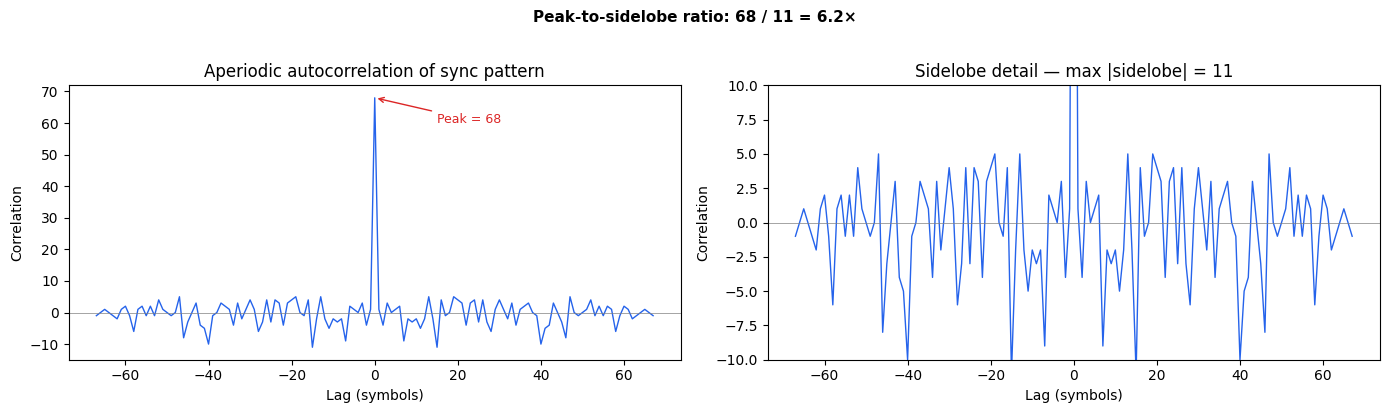

In [3]:
# --- Sync pattern autocorrelation ---
# A good sync pattern has a sharp peak at zero lag and low sidelobes.
# This is what makes it detectable in noise.
sync_bipolar = 1.0 - 2.0 * sync_pattern.astype(np.float64)  # 0 → +1, 1 → -1


def aperiodic_autocorrelation(seq: np.ndarray) -> np.ndarray:
    """Compute full aperiodic (linear) autocorrelation."""
    result = np.correlate(seq, seq, mode="full")
    return result  # length 2n-1, peak at index n-1


acorr = aperiodic_autocorrelation(sync_bipolar)
lags = np.arange(-(len(sync_bipolar) - 1), len(sync_bipolar))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Full autocorrelation
axes[0].plot(lags, acorr, color="#2563eb", linewidth=1)
axes[0].axhline(0, color="grey", linewidth=0.5)
axes[0].set_xlabel("Lag (symbols)")
axes[0].set_ylabel("Correlation")
axes[0].set_title("Aperiodic autocorrelation of sync pattern")
peak = acorr[len(sync_bipolar) - 1]
sidelobes = np.delete(acorr, len(sync_bipolar) - 1)
axes[0].annotate(
    f"Peak = {peak:.0f}",
    xy=(0, peak),
    xytext=(15, peak - 8),
    arrowprops=dict(arrowstyle="->", color="#dc2626"),
    fontsize=9,
    color="#dc2626",
)

# Zoom on sidelobes
axes[1].plot(lags, acorr, color="#2563eb", linewidth=1)
axes[1].axhline(0, color="grey", linewidth=0.5)
axes[1].set_ylim(-10, 10)
axes[1].set_xlabel("Lag (symbols)")
axes[1].set_ylabel("Correlation")
max_sidelobe = np.max(np.abs(sidelobes))
axes[1].set_title(f"Sidelobe detail — max |sidelobe| = {max_sidelobe:.0f}")
fig.suptitle(
    f"Peak-to-sidelobe ratio: {peak:.0f} / {max_sidelobe:.0f} = {peak / max_sidelobe:.1f}×",
    fontsize=11,
    fontweight="bold",
    y=1.02,
)

fig.tight_layout()
plt.show()

The sharp peak at zero lag and low sidelobes mean the receiver can
confidently identify the frame boundary even when the signal is buried in
noise. The sync detector cross-correlates the received symbols against the
known pattern and looks for a peak above a threshold — LunaLink's
`sync_detect` function does exactly this.

---

## 3. Subframe 1 — the BCH header

> **Spec:** §2.4.2 (LSIS-410, LSIS-415) — *Subframe 1 Message Specification*

Immediately after the sync pattern, the next 52 symbols carry **Subframe 1**
(SB1) — a tiny but critical header encoded with a
[BCH(51,8)](https://en.wikipedia.org/wiki/BCH_code) code using a
[generator polynomial](https://en.wikipedia.org/wiki/Generator_polynomial) of 763 (octal). It carries just
**9 bits** of information:

| Field | Bits | Range | Purpose | Spec |
|-------|------|-------|---------|------|
| FID (Frame Identifier) | 2 | 0–3 | Identifies frame type | Table 13 |
| TOI (Time of Interval) | 7 | 0–99 | Frame index within a 20-minute block | Table 13 |

The 2 MSBs are the FID and the 7 LSBs are the TOI (LSIS-415). The BCH
code expands these 9 bits into 52 symbols that can correct up to 2 bit
errors — enough to decode the header reliably at the operating SNR.

Currently, only **FID = 0** is defined (Table 15). FID values 1–3 are
reserved for future frame structures with different subframe layouts.

The TOI represents the time of the node clock epoch at the start (leading
edge) of the **next** 12-second frame (LSIS-415).

In [4]:
# --- BCH encoding example (reproducing spec Figure 8) ---
# Spec example: FID=0 (binary 00), TOI=69 (binary 1000101)
# SB1 data = 0|0|1|0|0|0|1|0|1 → padded hex 0x045
# Encoded field = 0x229F61DBB84A0
fid_example, toi_example = 0, 69
codeword = bch_encode(fid_example, toi_example)
print(f"FID = {fid_example}, TOI = {toi_example}")
print(f"SB1 data (9 bits): {''.join(str(b) for b in codeword[:9])}")

# Convert 9-bit data to hex (with 3 padding zeros as per spec Figure 8)
data_bits = "".join(str(b) for b in codeword[:9])
data_padded = "000" + data_bits  # 3 zeros padded to left for hex representation
data_hex = f"0x{int(data_padded, 2):03X}"
print(f"SB1 data (hex, padded): {data_hex}  (spec: 0x045)")

# Full 52-symbol encoded field
encoded_bits = "".join(str(b) for b in codeword)
encoded_hex = f"0x{int(encoded_bits, 2):013X}"
print(f"Encoded field (52 symbols): {encoded_bits}")
print(f"Encoded field (hex):        {encoded_hex}")
print("Spec Figure 8 (hex):        0x229F61DBB84A0")

FID = 0, TOI = 69
SB1 data (9 bits): 001000101
SB1 data (hex, padded): 0x045  (spec: 0x045)
Encoded field (52 symbols): 0010001010011111011000011101101110111000010010100000
Encoded field (hex):        0x229F61DBB84A0
Spec Figure 8 (hex):        0x229F61DBB84A0


In [5]:
# --- Decode round-trip ---
# Encode FID=0, TOI=42 and verify decode recovers the values
fid, toi = 0, 42
cw = bch_encode(fid, toi)
print(f"Encode: FID={fid}, TOI={toi} → {cw.shape[0]} symbols")

# Hard-decision decode
result = bch_decode(cw)
print(
    f"Decode: status={result.status.name}, FID={result.fid}, TOI={result.toi}, "
    f"hamming_distance={result.hamming_distance}"
)

# Flip 2 bits and decode again — BCH(51,8) corrects up to 2 errors
cw_corrupted = cw.copy()
cw_corrupted[10] ^= 1
cw_corrupted[30] ^= 1
result2 = bch_decode(cw_corrupted)
print(
    f"With 2 bit errors: status={result2.status.name}, FID={result2.fid}, "
    f"TOI={result2.toi}, hamming_distance={result2.hamming_distance}"
)

Encode: FID=0, TOI=42 → 52 symbols
Decode: status=OK, FID=Fid(0), TOI=Toi(42), hamming_distance=0
With 2 bit errors: status=OK, FID=Fid(0), TOI=Toi(42), hamming_distance=2


---

## 4. Subframe 2 — the always-on data channel

> **Spec:** §2.4.3.1.6 (LSIS-FID0-500, LSIS-FID0-510, LSIS-FID0-530) — *SB2 Message Specifications*

Subframe 2 is the **workhorse** — it is broadcast in **every frame** with an
**identical structure** (LSIS-FID0-500, LSIS-FID0-510). This makes it the
most reliable source of navigation data: even if the receiver only decodes
a single frame, it gets everything needed to compute a position fix.

SB2 carries 1,176 data bits + 24-bit [CRC](https://en.wikipedia.org/wiki/Cyclic_redundancy_check) = 1,200 bits total, [LDPC](https://en.wikipedia.org/wiki/Low-density_parity-check_code)-encoded
to 2,400 symbols (rate ½). Table 18 defines the overall split
(1,176 data + 24 CRC). The detailed field layout below reflects
LunaLink's implementation of the mandatory fields from LSIS-FID0-520
— the spec does not prescribe exact bit offsets within the data portion:

| Field | Bit offset | Bits | Content |
|-------|-----------|------|---------|
| WN | 0 | 13 | Week Number (0–8191) |
| ITOW | 13 | 9 | Interval Time of Week (0–503) |
| Health | 22 | 8 | LNSP node health status (MSG-G2) |
| CED | 30 | 896 | Clock and Ephemeris Data (MSG-G4) |
| Time Conv. | 926 | 224 | Time Conversions (MSG-G30) |
| Spare | 1150 | 26 | Alternating 0/1, starting with 0 (LSIS-300) |
| **Total** | | **1,176** | |

The mandatory content defined by the spec (LSIS-FID0-520):
- **Clock and Ephemeris Data** (CED, MSG-G4) — position and velocity of
  the transmitting [LNSP](https://en.wikipedia.org/wiki/LunaNet) node, plus clock corrections
- **Time of Transmission** (ToT, MSG-G8) — WN and ITOW fields
- **Health and Safety** (MSG-G2) — node health status
- **Time Conversions** (MSG-G30) — conversions between time scales

In [6]:
# --- Build a custom SB2 with meaningful time fields ---
# Construct SB2 data with WN=100, ITOW=42, and visualise the bit layout
sb2_data = np.zeros(SB2_DATA_BITS, dtype=np.uint8)

# Pack WN = 100 into bits 0-12 (MSB first, per LSIS-320)
wn = 100
for i in range(13):
    sb2_data[i] = (wn >> (12 - i)) & 1

# Pack ITOW = 42 into bits 13-21
itow = 42
for i in range(9):
    sb2_data[13 + i] = (itow >> (8 - i)) & 1

# Set spare bits to alternating 0/1 starting with 0 (LSIS-300)
for i in range(26):
    sb2_data[1150 + i] = i % 2

# Verify parse recovers the values
parsed = parse_sb2(sb2_data)
print(f"SB2 bit layout ({SB2_DATA_BITS} bits):")
print(f"  WN   = {parsed.wn} (bits 0–12)")
print(f"  ITOW = {parsed.itow} (bits 13–21)")
print(f"  First 30 bits: {''.join(str(b) for b in sb2_data[:30])}")
print(f"  Spare (last 26): {''.join(str(b) for b in sb2_data[1150:])}")

SB2 bit layout (1176 bits):
  WN   = 100 (bits 0–12)
  ITOW = 42 (bits 13–21)
  First 30 bits: 000000110010000010101000000000
  Spare (last 26): 01010101010101010101010101


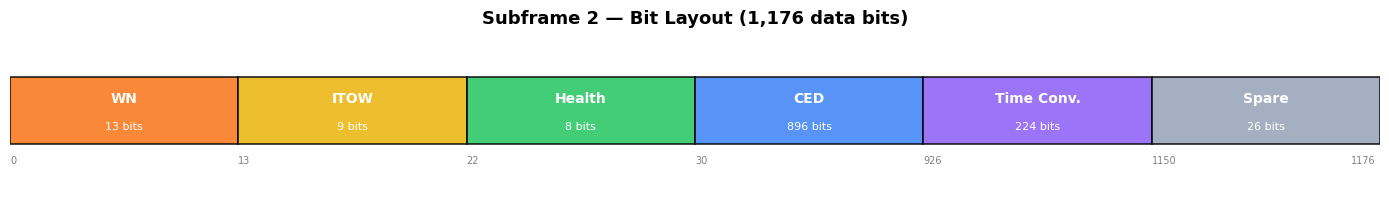

In [7]:
# --- Visualise SB2 bit layout ---
# Equal-width boxes so small fields are readable; bit counts shown inside.
fields = [
    ("WN", 13, "#f97316"),
    ("ITOW", 9, "#eab308"),
    ("Health", 8, "#22c55e"),
    ("CED", 896, "#3b82f6"),
    ("Time Conv.", 224, "#8b5cf6"),
    ("Spare", 26, "#94a3b8"),
]
n = len(fields)
fig, ax = plt.subplots(figsize=(14, 2.2))
ax.set_xlim(0, n)
ax.set_ylim(0, 3)
ax.axis("off")
ax.set_title(
    "Subframe 2 — Bit Layout (1,176 data bits)", fontsize=13, fontweight="bold"
)
offset = 0
for i, (name, bits, color) in enumerate(fields):
    ax.add_patch(
        plt.Rectangle(
            (i, 1),
            1,
            1.2,
            facecolor=color,
            edgecolor="black",
            linewidth=1.2,
            alpha=0.85,
            zorder=2,
        )
    )
    ax.text(
        i + 0.5,
        1.8,
        name,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color="white",
        zorder=3,
    )
    ax.text(
        i + 0.5,
        1.3,
        f"{bits} bits",
        ha="center",
        va="center",
        fontsize=8,
        color="white",
        zorder=3,
    )
    ax.text(i, 0.65, f"{offset}", ha="left", fontsize=7, color="grey")
    offset += bits
ax.text(n - 0.02, 0.65, f"{offset}", ha="right", fontsize=7, color="grey")
fig.tight_layout()
plt.show()

---

## 5. Subframes 3 & 4 — dynamic message channels

> **Spec:** §2.4.3.1.7–8 (LSIS-FID0-560, LSIS-FID0-600) — *SB3/SB4 Message Specifications*

Unlike SB2 (fixed structure, every frame), **SB3 and SB4** are
**dynamic** — their content changes from frame to frame, identified by a
type field in the first bits.

Each subframe carries 846 data bits + 24-bit CRC = 870 bits, LDPC-encoded
to 1,740 symbols (rate ½).

**SB3 layout** (Table 19):

| Field | Bits | Purpose |
|-------|------|---------|
| SB3 type | 4 or 6 {TBC} (LunaLink implements 6 bits) | Message type identifier |
| Data | 840 | Message payload |
| CRC | 24 | Integrity check |
| **Total** | **870** | |

**SB4 layout** (Table 20) is identical in structure.

The type field maps to a rich catalogue of [message types](https://en.wikipedia.org/wiki/Navigation_message) defined in
Table 21 of the spec. The LNSP decides which messages to broadcast and
when — the spec gives flexibility while ensuring interoperability.

In [8]:
# --- Message type catalogue (Table 21) ---
# Show the mapping of message types to subframes
table_21 = [
    ("MSG-G1", "LunaNet Network Access Info", "F", "SB4", "yes"),
    ("MSG-G2", "Health and Safety", "F", "SB2", "yes"),
    ("MSG-G3", "Antenna Properties", "O", "SB3 and/or SB4", "yes"),
    ("MSG-G4", "Clock & Ephemeris (CED)", "F", "SB2", "yes"),
    ("MSG-G5", "MOrbit Almanac", "F", "SB3 and/or SB4", "yes"),
    ("MSG-G8", "Time of Transmission (ToT)", "F", "SB1, SB2, SB3", "yes"),
    ("MSG-G10", "Maneuver", "O", "SB3 and/or SB4", "yes"),
    ("MSG-G11", "Attitude State/Ephemeris", "O", "SB3 and/or SB4", "yes"),
    ("MSG-G14", "Conjunction", "O", "SB3 and/or SB4", "no"),
    ("MSG-G15", "Maplet", "O", "SB4", "no"),
    ("MSG-G17", "Ancillary Info", "O", "SB4", "yes"),
    ("MSG-S19", "LunaSAR Acknowledge (LvL1)", "F", "SB3", "no"),
    ("MSG-S20", "LunaSAR Return (LvL2)", "F", "SB3", "yes*"),
    ("MSG-G22", "Acknowledge non-SAR", "O", "SB4", "no"),
    ("MSG-G23", "GNSS Augmentation", "O", "SB3 and/or SB4", "no"),
    ("MSG-G24", "Detection Alert", "F", "SB3", "no"),
    ("MSG-G25", "Science", "C", "SB4", "no"),
    ("MSG-G27", "UIS Response", "C", "SB4", "no"),
    ("MSG-G28", "User Schedule Notice", "C", "SB4", "yes"),
    ("MSG-G29", "FF Commands", "C", "SB4", "no"),
    ("MSG-G30", "Time Conversions", "F", "SB2", "yes"),
    ("MSG-G31", "Augmentation Diff. Corrections", "O", "SB3 and/or SB4", "yes"),
    ("MSG-G32", "Coordinate Frame Conversions", "F", "SB3 and/or SB4", "yes"),
]
print(f"{'MSG ID':<10} {'Title':<35} {'Cat':>3} {'Subframe':<18} {'LNIS V1.0':>9}")
print("─" * 80)
for msg_id, title, cat, sf, lnis in table_21:
    # F=Fundamental, O=Optional, C=Comm
    print(f"{msg_id:<10} {title:<35} {cat:>3} {sf:<18} {lnis:>9}")
print()
print("Category: F = Fundamental (mandatory), O = Optional, C = Comm service")
print("* MSG-S20: LunaNet 1.0 item, limited to reserved bit allocation")

MSG ID     Title                               Cat Subframe           LNIS V1.0
────────────────────────────────────────────────────────────────────────────────
MSG-G1     LunaNet Network Access Info           F SB4                      yes
MSG-G2     Health and Safety                     F SB2                      yes
MSG-G3     Antenna Properties                    O SB3 and/or SB4           yes
MSG-G4     Clock & Ephemeris (CED)               F SB2                      yes
MSG-G5     MOrbit Almanac                        F SB3 and/or SB4           yes
MSG-G8     Time of Transmission (ToT)            F SB1, SB2, SB3            yes
MSG-G10    Maneuver                              O SB3 and/or SB4           yes
MSG-G11    Attitude State/Ephemeris              O SB3 and/or SB4           yes
MSG-G14    Conjunction                           O SB3 and/or SB4            no
MSG-G15    Maplet                                O SB4                       no
MSG-G17    Ancillary Info              

In [9]:
# --- Parse SB3 and SB4 type fields ---
# Construct an SB3 with message type G5 (Almanac, type code 0x05)
sb3_data = np.zeros(SB3_DATA_BITS, dtype=np.uint8)
msg_type_g5 = 0x05  # MOrbit Almanac
for i in range(6):
    sb3_data[i] = (msg_type_g5 >> (5 - i)) & 1
parsed3 = parse_sb3(sb3_data)
print(f"SB3 type field: 0x{parsed3.type_raw:02X} → {parsed3.type.name}")
print(f"  Payload offset: {parsed3.data_offset} bits")
print(f"  Payload size:   {parsed3.payload_size} bits")

# SB4 with message type G1 (Network Access Info, type code 0x01)
sb4_data = np.zeros(SB3_DATA_BITS, dtype=np.uint8)  # SB4 same size as SB3
msg_type_g1 = 0x01
for i in range(6):
    sb4_data[i] = (msg_type_g1 >> (5 - i)) & 1
parsed4 = parse_sb4(sb4_data)
print(f"\nSB4 type field: 0x{parsed4.type_raw:02X} → {parsed4.type.name}")
print(f"  Payload offset: {parsed4.data_offset} bits")
print(f"  Payload size:   {parsed4.payload_size} bits")

SB3 type field: 0x05 → G5
  Payload offset: 6 bits
  Payload size:   840 bits

SB4 type field: 0x01 → G1
  Payload offset: 6 bits
  Payload size:   840 bits


---

## 6. Time of Transmission

> **Spec:** §2.5.5 (LSIS-720, LSIS-730) — *Time of Transmission (MSG-G8)*

The receiver reconstructs the **[time of transmission](https://en.wikipedia.org/wiki/Time_of_arrival)** ($t_F$) by combining
three fields from different parts of the frame:

$$t_F = WN \times SECWEEK + ITOW \times BI_d + TOI \times F_d + \Delta t_{LRT}$$

where (Table 22):

| Parameter | Value | Source | Spec |
|-----------|-------|--------|------|
| WN (Week Number) | 13 bits, 0–8191 | SB2 (bits 0–12) | LSIS-730 |
| ITOW (Interval Time of Week) | 9 bits, 0–503 | SB2 (bits 13–21) | LSIS-730 |
| TOI (Time of Interval) | 7 bits, 0–99 | SB1 (BCH-decoded) | LSIS-415 |
| $SECWEEK$ | 604,800 s | Constant | §2.5.5 |
| $BI_d$ (block interval) | 1,200 s (= 12 s × 100 frames) | Constant | §2.5.5 |
| $F_d$ (frame duration) | 12 s | Constant | §2.5.5 |
| $\Delta t_{LRT}$ | From MSG-G4 | Node Time offset vs LRT | §2.5.5 |

The time hierarchy (Figure 11 of the spec):
- **1 week** = 604,800 seconds
- **1 block interval (BI)** = 1,200 seconds = 20 minutes = 100 frames
- **504 BIs per week** (504 × 1,200 = 604,800), so ITOW ranges 0–503
- **1 frame** = 12 seconds, so TOI ranges 0–99 within each BI
- **WN** counts weeks from the [LunaNet Reference Time](https://en.wikipedia.org/wiki/Epoch_(astronomy)) (LRT) start epoch

In [10]:
# --- Time of Transmission computation ---
# Simulate a frame at WN=100, ITOW=42, TOI=7
wn, itow_val, toi_val = 100, 42, 7
tot_result = compute_tot(wn, itow_val, toi_val)
print("Time of Transmission:")
print(f"  WN   = {wn}")
print(f"  ITOW = {itow_val}")
print(f"  TOI  = {toi_val}")
print(f"  t_F  = {tot_result.t_f:.1f} seconds from LRT epoch")
print()

# Manual verification
SECWEEK = 604_800
BI_d = 1_200
F_d = 12
t_f_manual = wn * SECWEEK + itow_val * BI_d + toi_val * F_d
print(f"Manual check: {wn} × {SECWEEK} + {itow_val} × {BI_d} + {toi_val} × {F_d}")
print(f"            = {wn * SECWEEK} + {itow_val * BI_d} + {toi_val * F_d}")
print(f"            = {t_f_manual} seconds")
print(f"            = {t_f_manual / 86400:.2f} days from LRT epoch")
print(f"            = {t_f_manual / SECWEEK:.4f} weeks from LRT epoch")

Time of Transmission:
  WN   = 100
  ITOW = 42
  TOI  = 7
  t_F  = 60530484.0 seconds from LRT epoch

Manual check: 100 × 604800 + 42 × 1200 + 7 × 12
            = 60480000 + 50400 + 84
            = 60530484 seconds
            = 700.58 days from LRT epoch
            = 100.0835 weeks from LRT epoch


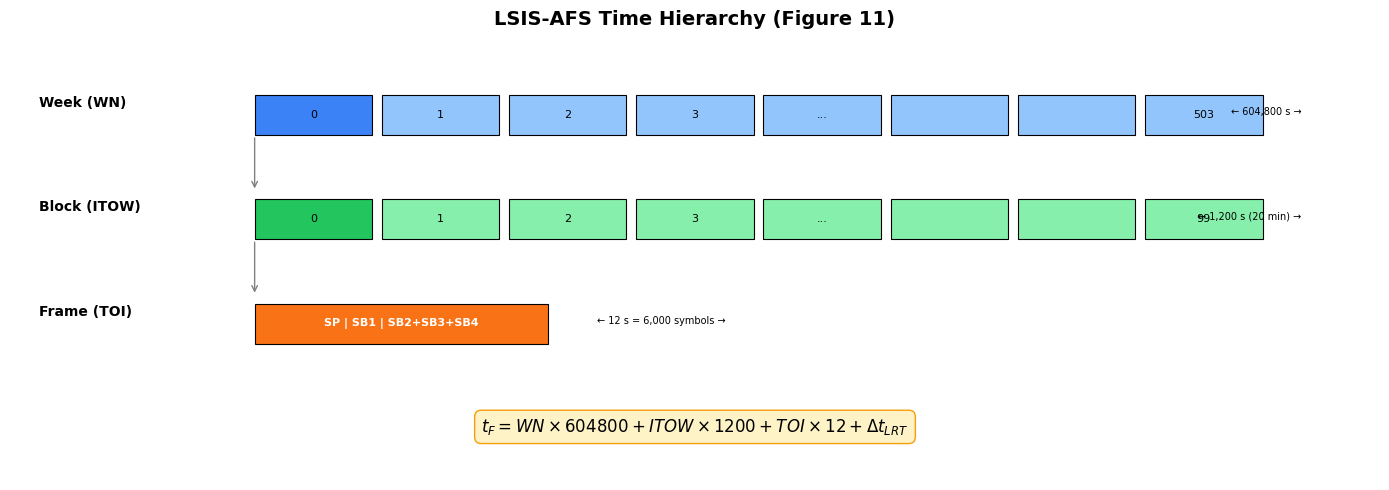

In [11]:
# --- Visualise the time hierarchy (Figure 11 style) ---
fig, ax = plt.subplots(figsize=(14, 5))
ax.set_xlim(0, 14)
ax.set_ylim(0, 5.5)
ax.axis("off")
ax.set_title(
    "LSIS-AFS Time Hierarchy (Figure 11)",
    fontsize=14,
    fontweight="bold",
    pad=10,
)

# Week level
y = 4.5
ax.text(0.3, y + 0.15, "Week (WN)", fontsize=10, fontweight="bold")
for i in range(8):
    x = 2.5 + i * 1.3
    color = "#3b82f6" if i == 0 else "#93c5fd"
    ax.add_patch(
        plt.Rectangle(
            (x, y - 0.2), 1.2, 0.5, facecolor=color, edgecolor="black", linewidth=0.8
        )
    )
    if i < 4:
        ax.text(x + 0.6, y + 0.05, str(i), ha="center", va="center", fontsize=8)
    elif i == 4:
        ax.text(x + 0.6, y + 0.05, "...", ha="center", va="center", fontsize=8)
    elif i == 7:
        ax.text(x + 0.6, y + 0.05, "503", ha="center", va="center", fontsize=8)
ax.text(13.2, y + 0.05, "← 604,800 s →", fontsize=7, ha="right")

# Block interval level
y = 3.2
ax.text(0.3, y + 0.15, "Block (ITOW)", fontsize=10, fontweight="bold")
ax.annotate(
    "",
    xy=(2.5, y + 0.4),
    xytext=(2.5, 4.3),
    arrowprops=dict(arrowstyle="->", color="grey", lw=1),
)
for i in range(8):
    x = 2.5 + i * 1.3
    color = "#22c55e" if i == 0 else "#86efac"
    ax.add_patch(
        plt.Rectangle(
            (x, y - 0.2), 1.2, 0.5, facecolor=color, edgecolor="black", linewidth=0.8
        )
    )
    if i < 4:
        ax.text(x + 0.6, y + 0.05, str(i), ha="center", va="center", fontsize=8)
    elif i == 4:
        ax.text(x + 0.6, y + 0.05, "...", ha="center", va="center", fontsize=8)
    elif i == 7:
        ax.text(x + 0.6, y + 0.05, "99", ha="center", va="center", fontsize=8)
ax.text(13.2, y + 0.05, "← 1,200 s (20 min) →", fontsize=7, ha="right")

# Frame level
y = 1.9
ax.text(0.3, y + 0.15, "Frame (TOI)", fontsize=10, fontweight="bold")
ax.annotate(
    "",
    xy=(2.5, y + 0.4),
    xytext=(2.5, 3.0),
    arrowprops=dict(arrowstyle="->", color="grey", lw=1),
)
ax.add_patch(
    plt.Rectangle(
        (2.5, y - 0.2), 3.0, 0.5, facecolor="#f97316", edgecolor="black", linewidth=0.8
    )
)
ax.text(
    4.0,
    y + 0.05,
    "SP | SB1 | SB2+SB3+SB4",
    ha="center",
    va="center",
    fontsize=8,
    color="white",
    fontweight="bold",
)
ax.text(6.0, y + 0.05, "← 12 s = 6,000 symbols →", fontsize=7)

# Formula
ax.text(
    7.0,
    0.6,
    r"$t_F = WN \times 604800 + ITOW \times 1200 + TOI \times 12 + \Delta t_{LRT}$",
    fontsize=12,
    ha="center",
    style="italic",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#fef3c7", edgecolor="#f59e0b"),
)

fig.tight_layout()
plt.show()

---

## 7. Interleaving — how SB2+SB3+SB4 are shuffled

We now know what goes into each subframe. Before they are transmitted,
there is one more encoding step.

> **Spec:** §2.4.3.1.5 (LSIS-FID0-470) — *Interleaving*

The 5,880 symbols from SB2 (2,400) + SB3 (1,740) + SB4 (1,740) are
concatenated and then **[block-interleaved](https://en.wikipedia.org/wiki/Burst_error-correcting_code#Block_interleaver)** using a 60×98 matrix. Symbols
are written **row-wise** (left to right, top to bottom) and read out
**column-wise** (top to bottom, left to right).

This spreads [burst errors](https://en.wikipedia.org/wiki/Burst_error) across all three subframes — a burst that
corrupts 60 consecutive transmitted symbols only damages one symbol per
row in the LDPC codeword, which the decoder handles easily.

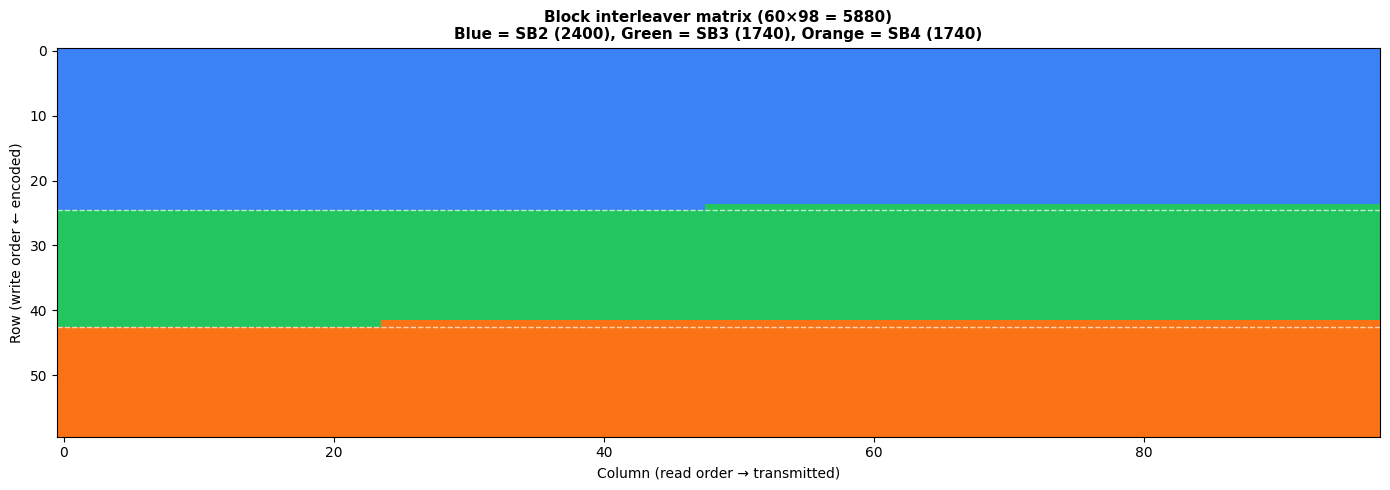

When reading column-wise, each column mixes symbols from all 3 subframes.
A burst of 60 consecutive errors hits one symbol per row — 
spread across the LDPC codeword, easily correctable.


In [12]:
# --- Visualise the interleaver matrix ---
# Show which subframe each cell belongs to
# Create a label array: 0=SB2, 1=SB3, 2=SB4
labels = np.zeros(INTERLEAVER_SIZE, dtype=np.int32)
labels[:SB2_LENGTH] = 0  # SB2: first 2400
labels[SB2_LENGTH : SB2_LENGTH + SB3_LENGTH] = 1  # SB3: next 1740
labels[SB2_LENGTH + SB3_LENGTH :] = 2  # SB4: last 1740
# Write row-wise into 60×98 matrix (as per spec)
matrix = labels.reshape(INTERLEAVER_ROWS, INTERLEAVER_COLS)
fig, ax = plt.subplots(figsize=(14, 5))
cmap = plt.cm.colors.ListedColormap(["#3b82f6", "#22c55e", "#f97316"])
ax.imshow(matrix, cmap=cmap, aspect="auto", interpolation="nearest")
ax.set_xlabel("Column (read order → transmitted)")
ax.set_ylabel("Row (write order ← encoded)")
ax.set_title(
    f"Block interleaver matrix ({INTERLEAVER_ROWS}×{INTERLEAVER_COLS} = "
    f"{INTERLEAVER_SIZE})\nBlue = SB2 (2400), Green = SB3 (1740), Orange = SB4 (1740)",
    fontsize=11,
    fontweight="bold",
)

# Show the boundary rows
sb2_last_row = (SB2_LENGTH - 1) // INTERLEAVER_COLS
sb3_last_row = (SB2_LENGTH + SB3_LENGTH - 1) // INTERLEAVER_COLS
ax.axhline(sb2_last_row + 0.5, color="white", linewidth=1, linestyle="--", alpha=0.7)
ax.axhline(sb3_last_row + 0.5, color="white", linewidth=1, linestyle="--", alpha=0.7)
fig.tight_layout()
plt.show()
print("When reading column-wise, each column mixes symbols from all 3 subframes.")
print(f"A burst of {INTERLEAVER_ROWS} consecutive errors hits one symbol per row — ")
print("spread across the LDPC codeword, easily correctable.")

---

## 8. Frame assembly — building a complete frame

> **Spec:** §2.4.3 (LSIS-FID0-430) — *Frame Structure*

With all the pieces in hand — sync pattern, BCH header, three subframes,
and the interleaver — let's build a complete frame from scratch. The frame assembly pipeline is:

1. **SB1:** Pack FID + TOI → BCH(51,8) encode → 52 symbols
2. **SB2:** 1,176 data bits → append CRC-24 → LDPC encode → 2,400 symbols
3. **SB3:** 846 data bits → append CRC-24 → LDPC encode → 1,740 symbols
4. **SB4:** 846 data bits → append CRC-24 → LDPC encode → 1,740 symbols
5. **Interleave:** Concatenate SB2+SB3+SB4 (5,880 symbols) → write into
   60×98 matrix row-wise → read out column-wise (LSIS-FID0-470)
6. **Assemble:** Sync pattern (68) + SB1 (52) + interleaved payload (5,880)
   = **6,000 symbols**

In [13]:
# --- Step-by-step frame assembly ---
# Choose time parameters
fid, toi = 0, 42
wn, itow_val = 100, 42

# Step 1: Build SB2 data with our time fields
sb2_data = np.zeros(SB2_DATA_BITS, dtype=np.uint8)
for i in range(13):  # WN
    sb2_data[i] = (wn >> (12 - i)) & 1
for i in range(9):  # ITOW
    sb2_data[13 + i] = (itow_val >> (8 - i)) & 1
for i in range(26):  # Spare: alternating 0/1 (LSIS-300)
    sb2_data[1150 + i] = i % 2

# Step 2: SB3 and SB4 — use almanac (G5) and network access (G1)
sb3_data = np.zeros(SB3_DATA_BITS, dtype=np.uint8)
for i in range(6):  # G5 = 0x05
    sb3_data[i] = (0x05 >> (5 - i)) & 1
sb4_data = np.zeros(SB3_DATA_BITS, dtype=np.uint8)
for i in range(6):  # G1 = 0x01
    sb4_data[i] = (0x01 >> (5 - i)) & 1

# Build the full frame
frame = frame_build(fid, toi, sb2_data, sb3_data, sb4_data)
print(f"Frame assembled: {frame.shape[0]} symbols")
print(f"  Sync pattern:  symbols [0:{SYNC_LENGTH}]")
print(f"  SB1 (BCH):     symbols [{SYNC_LENGTH}:{SYNC_LENGTH + SB1_LENGTH}]")
print(f"  Payload:       symbols [{SYNC_LENGTH + SB1_LENGTH}:{FRAME_LENGTH}]")
print(
    f"  Total:         {SYNC_LENGTH} + {SB1_LENGTH} + {PAYLOAD_LENGTH} = {FRAME_LENGTH}"
)

Frame assembled: 6000 symbols
  Sync pattern:  symbols [0:68]
  SB1 (BCH):     symbols [68:120]
  Payload:       symbols [120:6000]
  Total:         68 + 52 + 5880 = 6000


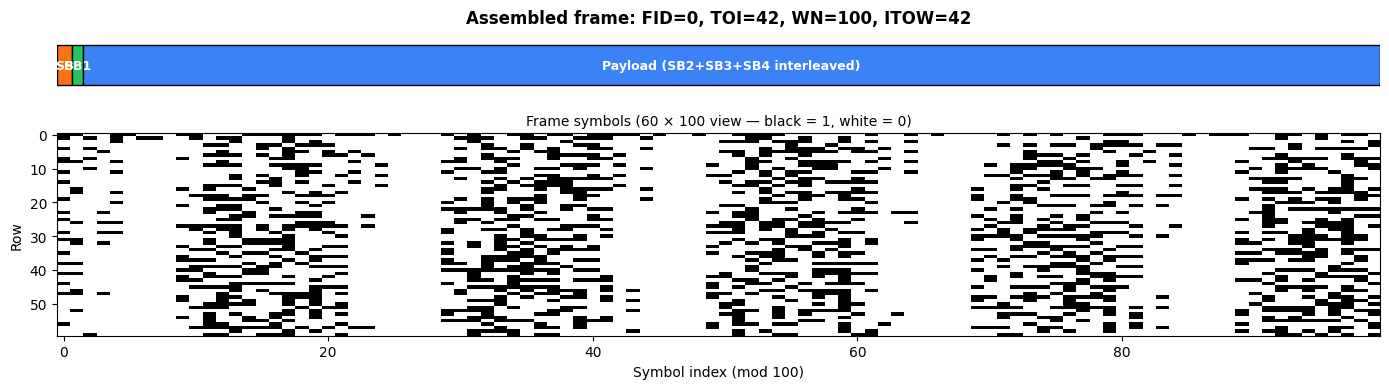

In [14]:
# --- Visualise the assembled frame as a bitmap ---
fig, axes = plt.subplots(2, 1, figsize=(14, 4), gridspec_kw={"height_ratios": [1, 3]})

# Top: frame structure with coloured regions
ax = axes[0]
ax.set_xlim(0, FRAME_LENGTH)
ax.set_ylim(0, 1)
ax.axis("off")
regions = [
    (0, SYNC_LENGTH, "SP", "#f97316"),
    (SYNC_LENGTH, SB1_LENGTH, "SB1", "#22c55e"),
    (
        SYNC_LENGTH + SB1_LENGTH,
        PAYLOAD_LENGTH,
        "Payload (SB2+SB3+SB4 interleaved)",
        "#3b82f6",
    ),
]
for start, width, label, color in regions:
    ax.add_patch(
        plt.Rectangle(
            (start, 0.2), width, 0.6, facecolor=color, edgecolor="black", linewidth=1
        )
    )
    ax.text(
        start + width / 2,
        0.5,
        label,
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="white",
    )
ax.set_title(
    f"Assembled frame: FID={fid}, TOI={toi}, WN={wn}, ITOW={itow_val}",
    fontsize=12,
    fontweight="bold",
)

# Bottom: actual symbol values as an image (60 rows × 100 cols)
ax = axes[1]
padded = np.zeros(6000, dtype=np.uint8)
padded[: len(frame)] = frame
frame_img = padded.reshape(60, 100)
ax.imshow(frame_img, cmap="binary", aspect="auto", interpolation="nearest")
ax.set_xlabel("Symbol index (mod 100)")
ax.set_ylabel("Row")
ax.set_title("Frame symbols (60 × 100 view — black = 1, white = 0)", fontsize=10)
fig.tight_layout()
plt.show()

---

## 9. Full round-trip — encode, transmit, decode

> **Spec:** §2.4 — Full pipeline

The ultimate test: build a frame with meaningful navigation data, convert
to soft symbols (simulating a noiseless channel), and decode — verifying
that every field comes back bit-exact.

In [15]:
# --- Full TX → RX round-trip ---
# Transmit
tx_frame, tx_iq = transmit_frame(
    prn_id=1,
    fid=fid,
    toi=toi,
    sb2_data=sb2_data,
    sb3_data=sb3_data,
    sb4_data=sb4_data,
)

# Convert to soft symbols (noiseless: 0 → +1.0, 1 → -1.0)
soft_symbols = np.where(tx_frame.symbols == 0, 1.0, -1.0).astype(np.float32)

# Receive
rx = receive_frame(soft_symbols)
print("Decode results:")
print(f"  All OK:       {rx.all_ok}")
print(f"  Sync metric:  {rx.sync_metric:.1f} / {SYNC_LENGTH} (perfect = {SYNC_LENGTH})")
print(f"  FID:          {rx.fid} (expected {fid})")
print(f"  TOI:          {rx.toi} (expected {toi})")
print(f"  SB2 LDPC:     {'converged' if rx.sb2.ldpc_converged else 'FAILED'}")
print(f"  SB2 CRC:      {'OK' if rx.sb2.crc_ok else 'FAILED'}")
print(f"  SB3 LDPC:     {'converged' if rx.sb3.ldpc_converged else 'FAILED'}")
print(f"  SB3 CRC:      {'OK' if rx.sb3.crc_ok else 'FAILED'}")
print(f"  SB4 LDPC:     {'converged' if rx.sb4.ldpc_converged else 'FAILED'}")
print(f"  SB4 CRC:      {'OK' if rx.sb4.crc_ok else 'FAILED'}")

Decode results:

  All OK:       True
  Sync metric:  68.0 / 68 (perfect = 68)
  FID:          0 (expected 0)
  TOI:          42 (expected 42)
  SB2 LDPC:     converged
  SB2 CRC:      OK
  SB3 LDPC:     converged
  SB3 CRC:      OK
  SB4 LDPC:     converged
  SB4 CRC:      OK


In [16]:
# --- Verify time reconstruction ---
print("Time of Transmission:")
print(f"  WN   = {rx.time.wn} (expected {wn})")
print(f"  ITOW = {rx.time.itow} (expected {itow_val})")
print(f"  TOI  = {rx.time.toi} (expected {toi})")
print(f"  t_F  = {rx.time.t_f:.1f} s from LRT epoch")
print(f"       = {rx.time.seconds_of_week:.1f} s into the week")

# Verify data integrity
sb2_match = np.array_equal(rx.sb2.data, sb2_data)
sb3_match = np.array_equal(rx.sb3.data, sb3_data)
sb4_match = np.array_equal(rx.sb4.data, sb4_data)
print("\nData integrity:")
print(f"  SB2 bit-exact: {sb2_match}")
print(f"  SB3 bit-exact: {sb3_match}")
print(f"  SB4 bit-exact: {sb4_match}")

Time of Transmission:
  WN   = 100 (expected 100)
  ITOW = 42 (expected 42)
  TOI  = 42 (expected 42)
  t_F  = 60530904.0 s from LRT epoch
       = 50904.0 s into the week

Data integrity:
  SB2 bit-exact: True
  SB3 bit-exact: True
  SB4 bit-exact: True


---

## 10. Sync detection in noise

The round-trip above used noiseless symbols — a perfect channel.
In a real receiver, the sync pattern must be found in a noisy stream.
Let's add [Gaussian noise](https://en.wikipedia.org/wiki/Additive_white_Gaussian_noise) to the soft symbols and see how the sync
detector performs — the correlation peak should stand out even at low SNR.

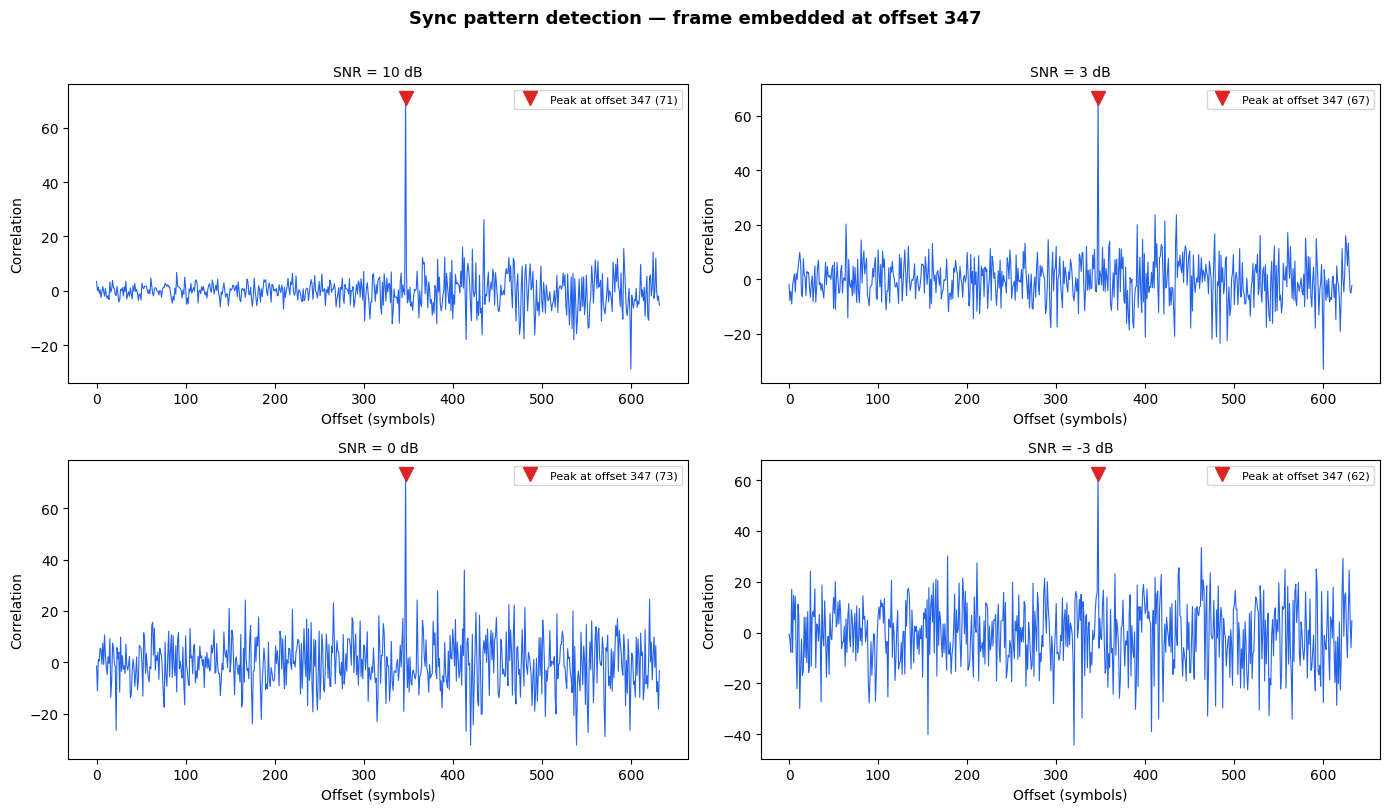

In [17]:
# --- Sync detection at different noise levels ---
# Embed the frame at a random offset inside a longer noise stream,
# then show cross-correlation finding the sync pattern.
rng = np.random.default_rng(42)
snr_dbs = [10.0, 3.0, 0.0, -3.0]
embed_offset = 347  # where the frame starts inside the stream
stream_len = embed_offset + FRAME_LENGTH + 200
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
sync_bipolar = np.where(sync_pattern == 0, 1.0, -1.0).astype(np.float64)
for ax, snr_db in zip(axes.flat, snr_dbs):
    # Build a noise stream with the frame embedded at embed_offset
    sigma = 10 ** (-snr_db / 20)
    stream = rng.normal(0, sigma, size=stream_len).astype(np.float64)
    stream[embed_offset : embed_offset + FRAME_LENGTH] += np.where(
        tx_frame.symbols == 0, 1.0, -1.0
    )
    # Cross-correlate the first 700 symbols against the sync pattern
    search_window = 700
    correlation = np.correlate(stream[:search_window], sync_bipolar, mode="valid")
    peak_idx = np.argmax(np.abs(correlation))
    peak_val = correlation[peak_idx]
    ax.plot(correlation, color="#2563eb", linewidth=0.8)
    ax.plot(
        peak_idx,
        peak_val,
        "v",
        color="#dc2626",
        markersize=10,
        zorder=5,
        label=f"Peak at offset {peak_idx} ({peak_val:.0f})",
    )
    ax.set_title(f"SNR = {snr_db:.0f} dB", fontsize=10)
    ax.set_xlabel("Offset (symbols)")
    ax.set_ylabel("Correlation")
    ax.legend(fontsize=8, loc="upper right")
fig.suptitle(
    f"Sync pattern detection — frame embedded at offset {embed_offset}",
    fontsize=13,
    fontweight="bold",
    y=1.01,
)
fig.tight_layout()
plt.show()

---

## 11. Spec compliance

| Requirement | Status | Evidence |
|---|---|---|
| LSIS-310: Frame = SP + SB1 + subframes | Verified | `frame_build` produces 6,000 symbols |
| LSIS-320: MSB-first bit ordering | Verified | WN/ITOW pack/parse round-trip |
| LSIS-330: Sync pattern per Table 12 | Verified | Hex matches `CC63F74536F49E04A` |
| LSIS-340: SP uncoded | Verified | First 68 symbols are raw pattern |
| LSIS-410/415: SB1 = FID(2) + TOI(7) via BCH(51,8) | Verified | Encode/decode round-trip |
| LSIS-FID0-430: FID=0 frame structure | Verified | Figure 9 reproduced |
| LSIS-FID0-470: 60×98 interleaver | Verified | Interleaver matrix visualised |
| LSIS-FID0-500/510: SB2 in every frame, fixed structure | Verified | Bit layout matches Table 18 |
| LSIS-720/730: ToT = WN×604800 + ITOW×1200 + TOI×12 | Verified | `compute_tot` matches manual |
| LSIS-300: Spare bits = alternating 0/1, start with 0 | Verified | SB2 spare field |
| Full TX→RX round-trip | Verified | All fields bit-exact after noiseless decode |

---

## Summary

| Component | Size | Content | Encoding | Spec |
|-----------|------|---------|----------|------|
| Sync Pattern (SP) | 68 symbols | Fixed detection sequence | None (uncoded) | §2.4.1.2, LSIS-330 |
| Subframe 1 (SB1) | 52 symbols | FID (2 bits) + TOI (7 bits) | BCH(51,8) | §2.4.2, LSIS-410 |
| Subframe 2 (SB2) | 2,400 symbols | WN + ITOW + Health + CED + Time Conv. | CRC-24 + LDPC ½ | §2.4.3.1.6, LSIS-FID0-530 |
| Subframe 3 (SB3) | 1,740 symbols | Dynamic: almanac, manoeuvre, augmentation... | CRC-24 + LDPC ½ | §2.4.3.1.7, LSIS-FID0-560 |
| Subframe 4 (SB4) | 1,740 symbols | Dynamic: network access, science, alerts... | CRC-24 + LDPC ½ | §2.4.3.1.8, LSIS-FID0-600 |
| Block interleaver | 5,880 symbols | SB2+SB3+SB4 shuffled | 60×98 write-row/read-col | §2.4.3.1.5, LSIS-FID0-470 |
| **Total frame** | **6,000 symbols** | **12 seconds at 500 sps** | | **§2.4.1, LSIS-310** |

**Key relationships:**
- $6{,}000 = 68 + 52 + 5{,}880$ — sync + header + payload
- $5{,}880 = 2{,}400 + 1{,}740 + 1{,}740$ — SB2 + SB3 + SB4 (all LDPC rate ½)
- $5{,}880 = 60 \times 98$ — interleaver dimensions
- $t_F = WN \times 604{,}800 + ITOW \times 1{,}200 + TOI \times 12$ — time reconstruction

A possible future tutorial on signal generation would show how frame symbols
are spread and modulated onto the AFS-I and AFS-Q channels.

### API quick reference

Full signatures are in the API reference (`docs/api.rst`).

- `frame_build(fid, toi, sb2, sb3, sb4)` — Build complete 6,000-symbol frame
- `receive_frame(symbols)` — Decode frame from soft symbols
- `transmit_frame(prn_id, fid, toi, ...)` — Build and modulate a frame
- `bch_encode(fid, toi)` — BCH(51,8) encode SB1 header
- `sync_detect(symbols)` — Detect sync pattern via cross-correlation
- `parse_sb2(data)` — Extract WN, ITOW from decoded SB2
- `compute_tot(wn, itow, toi)` — Compute time of transmission